# Aprendizado Supervisionado no Neurônio Perceptron

## Trabalho Redes Neurais 2.1
### Dupla: 

1. Izabella de Lima Catrinck - 2315310033 

2. Vinícius Castro Coutinho - 23153100?9

In [69]:
import numpy as np
import os
from pathlib import Path
import io
import matplotlib.pyplot as plt
from contextlib import redirect_stdout
from prettytable import PrettyTable

# Parte I – Resolvendo um Problema Linearmente Separável

In [70]:
npfile = Path("data/dataAll20262.npy")
if not npfile.exists():
  os.rename("data/dataAll20262.txt", "data/dataAll20262.npy")

input_array = np.load(npfile)
input_array.view()

array([[[ 547.91209711, -122.2431205 ,    1.        ]],

       [[ 717.19583982,  394.73605812,    0.        ]],

       [[-811.64530422,  951.24470327,    0.        ]],

       ...,

       [[ -49.38876423,  507.54135929,    0.        ]],

       [[-429.75519917, -329.90624499,    1.        ]],

       [[ 691.39880129,   40.14382452,    1.        ]]],
      shape=(1000, 1, 3))

In [71]:
class Neuron:
  def __init__(
      self, learning_rate=0.1, threshold=0, initial_weights_interval=(-0.5, 0.5001),
      use_bias=False
    ):
    self.learning_rate = learning_rate
    self.threshold = threshold
    self.use_bias = use_bias
    self.epoch = 0
    self.weight_adjustments = 0
    # Sem bias: pesos [w1, w2]. Com bias: pesos [w1, w2, bias]
    self.weights = np.random.uniform(
        low=initial_weights_interval[0], high=initial_weights_interval[1],
        size=3 if use_bias else 2
      )

    if use_bias:
      print(f"Vetor inicial de pesos (w1, w2, bias):\n{self.weights}")
    else:
      print(f"Vetor inicial de pesos:\n{self.weights}")

  def step_activation_function(self, x_weighted_sum):
    if x_weighted_sum >= self.threshold:
      return 1
    else:
      return 0

  def inputs(self, x: np.ndarray):
    """Entradas do exemplo; com bias, acrescenta a entrada fixa 1"""
    if self.use_bias:
      return np.array([x[0], x[1], 1.0])
    return x[:2]

  def weighted_sum(self, x: np.ndarray):
    return np.dot(self.weights, self.inputs(x))

  def calculate_error(self, predicted_y: int, x:np.ndarray):
    return x[2] - predicted_y

  def check_convergence(self, array):
    for x in array[0:, 0]:
        u = self.weighted_sum(x)

        predicted_y = self.step_activation_function(u)

        error = self.calculate_error(predicted_y, x)

        if error:
          print("Não convergiu")
          return False
    print("Convergiu")
    return True

  def graph(self, input_array):
    import matplotlib.pyplot as plt

    examples = input_array[:, 0, :]
    class_zero = examples[:, 2] == 0
    class_one = examples[:, 2] == 1
    bias = self.weights[2] if self.use_bias else 0

    plt.figure(figsize=(9, 6))
    plt.scatter(
        examples[class_zero, 0], examples[class_zero, 1],
        color="red", label="Classe 0", alpha=0.75, edgecolors="white"
      )
    plt.scatter(
        examples[class_one, 0], examples[class_one, 1],
        color="blue", label="Classe 1", alpha=0.75, edgecolors="white"
      )

    if abs(self.weights[1]) > np.finfo(float).eps:
      x_values = np.array([examples[:, 0].min(), examples[:, 0].max()])
      y_values = (self.threshold - bias - self.weights[0] * x_values) / self.weights[1]
      plt.plot(x_values, y_values, color="black", linewidth=2,
               label="Fronteira de decisão")
    elif abs(self.weights[0]) > np.finfo(float).eps:
      x_boundary = (self.threshold - bias) / self.weights[0]
      plt.axvline(x_boundary, color="black", linewidth=2,
                  label="Fronteira de decisão")

    plt.title(f"Classificação pelo Perceptron após {self.epoch} épocas")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.grid(True, alpha=0.25)
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
    plt.tight_layout()
    plt.show()

  def train_to_convergence(self, input_array):
    running = True
    while running:
      running = False

      self.epoch += 1
      for x in input_array[0:, 0]:
        u = self.weighted_sum(x)

        predicted_y = self.step_activation_function(u)

        error = self.calculate_error(predicted_y, x)

        if error:
          running = True
          self.weight_adjustments += 1
          self.weights += (error * self.learning_rate * self.inputs(x))

    print(f"Número de épocas:{self.epoch}")
    print(f"Número de ajustes nos pesos:{self.weight_adjustments}")
    self.graph(input_array)

  def train(self, input_array):
    """Trains neuron for 01 epoch"""
    self.epoch += 1
    for x in input_array[0:, 0]:
      u = self.weighted_sum(x)

      predicted_y = self.step_activation_function(u)

      error = self.calculate_error(predicted_y, x)

      if error:
        self.weight_adjustments += 1
        self.weights += (error * self.learning_rate * self.inputs(x))

Vetor inicial de pesos:
[-0.24275257 -0.42479704]
Número de épocas:4
Número de ajustes nos pesos:65


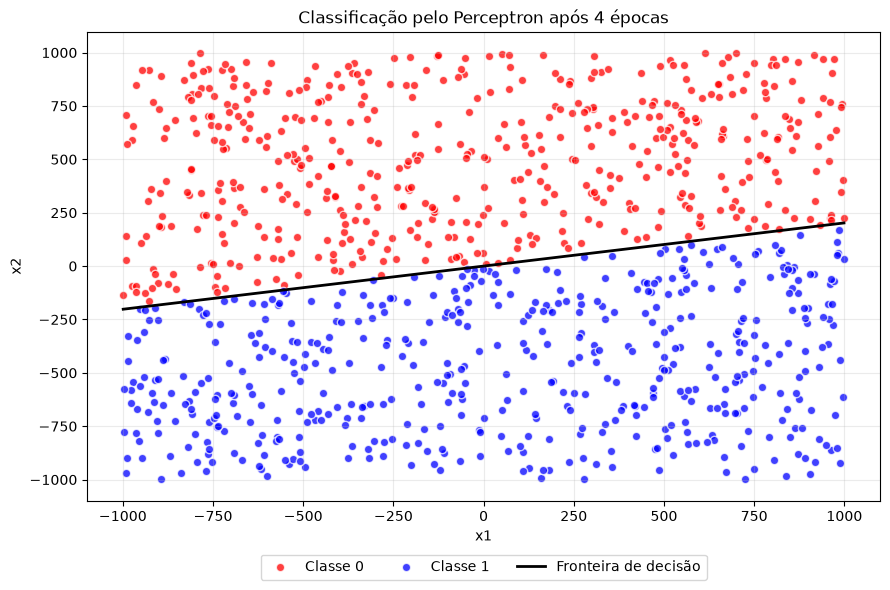

In [72]:
neuronio = Neuron()
neuronio.train_to_convergence(input_array)

# Parte II – Experimentação

In [ ]:
team_id = (3 + 9) % 4

npfile = Path(f"data/data{team_id}20262.npy")
if not npfile.exists():
  os.rename(f"data/data{team_id}20262.txt", npfile)

team_array = np.load(npfile)

mu = team_array[:, 0, :2].mean(axis=0)
sigma = team_array[:, 0, :2].std(axis=0)

team_scaled = team_array.copy()
team_scaled[:, 0, :2] = (team_array[:, 0, :2] - mu) / sigma

In [74]:
learning_rates = [0.4, 0.1, 0.01]
intervals = [(-100, 100), (-0.5, 0.5)]
repetitions = 10
MAX_EPOCHS = 5000

def run_once(data, learning_rate, interval):
  with redirect_stdout(io.StringIO()):
    neuron = Neuron(learning_rate=learning_rate, initial_weights_interval=interval, use_bias=True)

  for _ in range(MAX_EPOCHS):
    adjustments_before = neuron.weight_adjustments
    neuron.train(data)  # treina 1 época

    if neuron.weight_adjustments == adjustments_before:
      return neuron.weight_adjustments, neuron.epoch, True

  return neuron.weight_adjustments, neuron.epoch, False

In [75]:
results = {}

for lr in learning_rates:
  for interval in intervals:
    adjustments = []
    epochs = []

    for _ in range(repetitions):
      total_adjustments, total_epochs, converged = run_once(team_scaled, lr, interval)

      if not converged:
        print(f"Atenção: não convergiu em {MAX_EPOCHS} épocas (η={lr}, I={interval})")

      adjustments.append(total_adjustments)
      epochs.append(total_epochs)

    results[(lr, interval)] = {"adjustments": adjustments, "epochs": epochs}

print("Experimentos finalizados.")

Experimentos finalizados.


In [76]:
table = PrettyTable()
table.field_names = [
    "Taxa de Aprendizado", "Intervalo de Pesos", "Qtde Ajustes", "Min Épocas", "Max Épocas"
]

for (lr, interval), r in results.items():
  table.add_row([
      f"η = {lr}",
      f"({interval[0]}, +{interval[1]})",
      f"{np.mean(r['adjustments']):.2f} ± {np.std(r['adjustments']):.2f}",
      min(r["epochs"]),
      max(r["epochs"]),
  ])

print(table)

+---------------------+--------------------+-------------------+------------+------------+
| Taxa de Aprendizado | Intervalo de Pesos |    Qtde Ajustes   | Min Épocas | Max Épocas |
+---------------------+--------------------+-------------------+------------+------------+
|       η = 0.4       |    (-100, +100)    |  738.50 ± 682.73  |     2      |    224     |
|       η = 0.4       |    (-0.5, +0.5)    |  808.90 ± 870.49  |     14     |    478     |
|       η = 0.1       |    (-100, +100)    |  795.80 ± 381.17  |     6      |    165     |
|       η = 0.1       |    (-0.5, +0.5)    |  1067.30 ± 790.48 |     11     |    377     |
|       η = 0.01      |    (-100, +100)    | 7526.90 ± 3608.74 |     31     |    284     |
|       η = 0.01      |    (-0.5, +0.5)    |  464.10 ± 386.47  |     3      |    191     |
+---------------------+--------------------+-------------------+------------+------------+


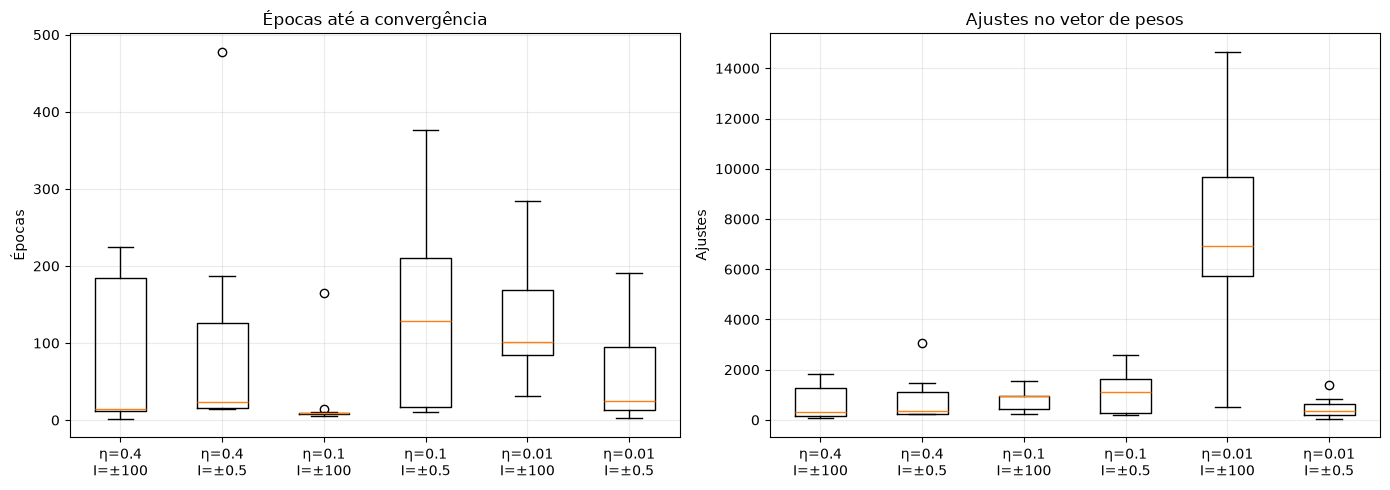

In [77]:
labels = [f"η={lr}\nI=±{interval[1]}" for (lr, interval) in results]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].boxplot([r["epochs"] for r in results.values()], tick_labels=labels)
axes[0].set_title("Épocas até a convergência")
axes[0].set_ylabel("Épocas")
axes[0].grid(True, alpha=0.25)

axes[1].boxplot([r["adjustments"] for r in results.values()], tick_labels=labels)
axes[1].set_title("Ajustes no vetor de pesos")
axes[1].set_ylabel("Ajustes")
axes[1].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()